## Project objectives

This is a **question-driven EDA**, not a collection of random charts. Each section follows:

**Question → Data/Calculation → Visualization → Finding → Business Interpretation**

The project focuses on:
- job demand and hiring activity
- salary and compensation
- experience level
- work arrangement and remote eligibility
- locations and industries
- skill demand and skill combinations
- application competitiveness
- data quality and limitations

In [1]:
import warnings
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Put the Kaggle ZIP (jobb.zip) in the same folder as this notebook.
# The notebook will automatically extract it the first time it runs.
BASE_DIR = Path(".")
DATA_DIR = BASE_DIR / "job_project_data"
ZIP_PATH = BASE_DIR / "jobb.zip"

if not (DATA_DIR / "postings.csv").exists() and ZIP_PATH.exists():
    DATA_DIR.mkdir(exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(DATA_DIR)

# Fallback for the uploaded files in this ChatGPT environment.
if not (DATA_DIR / "postings.csv").exists() and Path("/mnt/data/job_project_data/postings.csv").exists():
    DATA_DIR = Path("/mnt/data/job_project_data")

POSTINGS = DATA_DIR / "postings.csv"
if not POSTINGS.exists():
    raise FileNotFoundError("Place jobb.zip beside this notebook, or extract the Kaggle dataset into job_project_data/.")
print("Using:", POSTINGS)

Using: job_project_data/postings.csv


In [2]:
df = pd.read_csv(POSTINGS)
print("Shape:", df.shape)
display(df.head())

Shape: (123849, 31)


,job_id,company_name,title,description,max_salary,pay_period,location,company_id,views,med_salary,min_salary,formatted_work_type,applies,original_listed_time,remote_allowed,job_posting_url,application_url,application_type,expiry,closed_time,formatted_experience_level,skills_desc,listed_time,posting_domain,sponsored,work_type,currency,compensation_type,normalized_salary,zip_code,fips
0,921716,Corcoran Sawyer Smith,Marketing Coordinator,Job descriptionA leading real estate firm in N...,20.00,HOURLY,"Princeton, NJ","2,774,458.00",20.00,NaN,17.00,Full-time,2.00,"1,713,397,508,000.00",NaN,https://www.linkedin.com/jobs/view/921716/?trk...,NaN,ComplexOnsiteApply,"1,715,989,508,000.00",NaN,NaN,Requirements: \n\nWe are seeking a College or ...,"1,713,397,508,000.00",NaN,0,FULL_TIME,USD,BASE_SALARY,"38,480.00","8,540.00","34,021.00"
1,1829192,NaN,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committ...",50.00,HOURLY,"Fort Collins, CO",NaN,1.00,NaN,30.00,Full-time,NaN,"1,712,857,887,000.00",NaN,https://www.linkedin.com/jobs/view/1829192/?tr...,NaN,ComplexOnsiteApply,"1,715,449,887,000.00",NaN,NaN,NaN,"1,712,857,887,000.00",NaN,0,FULL_TIME,USD,BASE_SALARY,"83,200.00","80,521.00","8,069.00"
2,10998357,The National Exemplar,Assitant Restaurant Manager,The National Exemplar is accepting application...,"65,000.00",YEARLY,"Cincinnati, OH","64,896,719.00",8.00,NaN,"45,000.00",Full-time,NaN,"1,713,277,614,000.00",NaN,https://www.linkedin.com/jobs/view/10998357/?t...,NaN,ComplexOnsiteApply,"1,715,869,614,000.00",NaN,NaN,We are currently accepting resumes for FOH - A...,"1,713,277,614,000.00",NaN,0,FULL_TIME,USD,BASE_SALARY,"55,000.00","45,202.00","39,061.00"
3,23221523,"Abrams Fensterman, LLP",Senior Elder Law / Trusts and Estates Associat...,Senior Associate Attorney - Elder Law / Trusts...,"175,000.00",YEARLY,"New Hyde Park, NY","766,262.00",16.00,NaN,"140,000.00",Full-time,NaN,"1,712,895,812,000.00",NaN,https://www.linkedin.com/jobs/view/23221523/?t...,NaN,ComplexOnsiteApply,"1,715,487,812,000.00",NaN,NaN,This position requires a baseline understandin...,"1,712,895,812,000.00",NaN,0,FULL_TIME,USD,BASE_SALARY,"157,500.00","11,040.00","36,059.00"
4,35982263,NaN,Service Technician,Looking for HVAC service tech with experience ...,"80,000.00",YEARLY,"Burlington, IA",NaN,3.00,NaN,"60,000.00",Full-time,NaN,"1,713,451,943,000.00",NaN,https://www.linkedin.com/jobs/view/35982263/?t...,NaN,ComplexOnsiteApply,"1,716,043,943,000.00",NaN,NaN,NaN,"1,713,451,943,000.00",NaN,0,FULL_TIME,USD,BASE_SALARY,"70,000.00","52,601.00","19,057.00"


## 1. Dataset structure and quality

### Question 1 — Do we have enough data and the required variable types for meaningful EDA?

We verify row count, columns, data types, missingness, duplicates and time coverage before drawing conclusions.

In [3]:
print("Rows:", len(df))
print("Columns:", df.shape[1])
print("Numeric columns:", len(df.select_dtypes(include=np.number).columns))
print("Text/categorical columns:", len(df.select_dtypes(include="object").columns))
print("Duplicate rows:", df.duplicated().sum())
print("\nNumeric columns:")
print(df.select_dtypes(include=np.number).columns.tolist())
print("\nText/categorical columns:")
print(df.select_dtypes(include="object").columns.tolist())

Rows: 123849
Columns: 31
Numeric columns: 16
Text/categorical columns: 15


Duplicate rows: 0

Numeric columns:
['job_id', 'max_salary', 'company_id', 'views', 'med_salary', 'min_salary', 'applies', 'original_listed_time', 'remote_allowed', 'expiry', 'closed_time', 'listed_time', 'sponsored', 'normalized_salary', 'zip_code', 'fips']

Text/categorical columns:
['company_name', 'title', 'description', 'pay_period', 'location', 'formatted_work_type', 'job_posting_url', 'application_url', 'application_type', 'formatted_experience_level', 'skills_desc', 'posting_domain', 'work_type', 'currency', 'compensation_type']


In [4]:
missing = pd.DataFrame({"missing_count": df.isna().sum(), "missing_pct": df.isna().mean().mul(100)}).sort_values("missing_pct", ascending=False)
display(missing.head(20))

,missing_count,missing_pct
closed_time,122776,99.13
skills_desc,121410,98.03
med_salary,117569,94.93
remote_allowed,108603,87.69
applies,100529,81.17
min_salary,94056,75.94
max_salary,94056,75.94
currency,87776,70.87
compensation_type,87776,70.87
pay_period,87776,70.87


**Data-quality interpretation:** salary, applications, remote eligibility and closed-time fields contain substantial missingness. Missing values should not be silently changed to zero; missingness itself can carry business meaning.

## 1.1 Data cleaning

### Question 1B — Is the raw data clean enough to analyse, and what needs fixing before we do?

The quality checks above show the raw file is structurally sound but has formatting and validity issues. Cleaning is kept conservative and consistent with the project principles: **missing values are preserved (never filled with zero) and salary outliers are not deleted** (they are investigated in Section 16).

Steps applied:
1. Remove exact duplicate rows and duplicate `job_id` values.
2. Trim stray leading/trailing whitespace in text columns and convert blank strings to missing.
3. Convert identifier columns (`company_id`, `zip_code`, `fips`) to integer IDs (nullable).
4. Treat impossible salary values (zero or negative) as missing rather than as real pay.
5. Verify logical consistency (min ≤ max salary, applies ≤ views).

In [5]:
rows_before = len(df)

# 1. Duplicates
df = df.drop_duplicates().drop_duplicates(subset="job_id", keep="first").reset_index(drop=True)
print("Duplicates removed:", rows_before - len(df))

# 2. Trim whitespace in text columns; blank strings -> missing
text_cols = df.select_dtypes(include=["object", "string"]).columns
ws_fixed = {}
for c in text_cols:
    s = df[c]
    cleaned = s.str.strip()
    ws_fixed[c] = int((s.notna() & (s != cleaned)).sum())
    df[c] = cleaned.replace("", np.nan)
print("\nText values with whitespace trimmed (columns affected):")
print({k: v for k, v in ws_fixed.items() if v})

# 3. Identifier columns -> nullable integer
for c in ["company_id", "zip_code", "fips"]:
    df[c] = df[c].astype("Int64")

# 4. Impossible salary values (<= 0) -> missing
salary_cols = ["min_salary", "max_salary", "med_salary", "normalized_salary"]
invalid = {c: int((df[c] <= 0).sum()) for c in salary_cols}
print("\nNon-positive salary values set to missing:", invalid)
for c in salary_cols:
    df.loc[df[c] <= 0, c] = np.nan

# 5. Logical consistency checks
print("\nmin_salary > max_salary:", int((df.min_salary > df.max_salary).sum()))
print("applies > views:", int((df.applies > df.views).sum()))
print("Negative views/applies:", int(((df.views < 0) | (df.applies < 0)).sum()))

print(f"\nRows before: {rows_before:,} | Rows after: {len(df):,}")

Duplicates removed: 0



Text values with whitespace trimmed (columns affected):
{'company_name': 787, 'title': 1977, 'description': 19593, 'skills_desc': 1420}

Non-positive salary values set to missing: {'min_salary': 0, 'max_salary': 0, 'med_salary': 14, 'normalized_salary': 14}

min_salary > max_salary: 0
applies > views: 0
Negative views/applies: 0

Rows before: 123,849 | Rows after: 123,849


## 2. Date preparation

### Question 2 — What period does the dataset actually cover?

Unix timestamps are converted to datetime. `original_listed_time` provides the broader posting timeline.

In [6]:
for c in ["original_listed_time", "listed_time", "expiry", "closed_time"]:
    df[c + "_dt"] = pd.to_datetime(df[c], unit="ms", errors="coerce")
print("Original listed period:", df.original_listed_time_dt.min(), "to", df.original_listed_time_dt.max())
print("Listed period:", df.listed_time_dt.min(), "to", df.listed_time_dt.max())
df["listed_year"] = df.original_listed_time_dt.dt.year
df["listed_month"] = df.original_listed_time_dt.dt.to_period("M").astype(str)

Original listed period: 2023-12-05 21:08:53 to 2024-04-20 00:26:43
Listed period: 2024-03-24 21:50:14 to 2024-04-20 00:26:56


,listed_month,postings,median_views,median_applies
0,2023-12,3,141.00,3.50
1,2024-01,7,410.00,15.00
2,2024-02,9,125.00,5.50
3,2024-03,1815,5.00,2.00
4,2024-04,122015,4.00,3.00


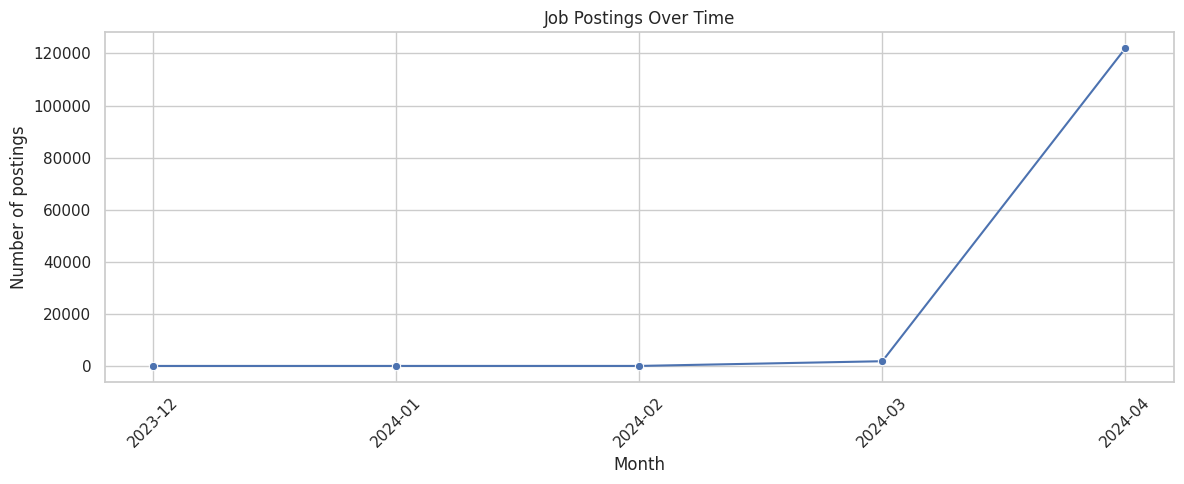

In [7]:
monthly = df.groupby("listed_month", as_index=False).agg(postings=("job_id","count"), median_views=("views","median"), median_applies=("applies","median"))
display(monthly)
plt.figure(figsize=(12,5)); sns.lineplot(data=monthly, x="listed_month", y="postings", marker="o")
plt.xticks(rotation=45); plt.title("Job Postings Over Time"); plt.xlabel("Month"); plt.ylabel("Number of postings"); plt.tight_layout(); plt.show()

## 3. Overall job-market profile

### Question 3 — What does the job market represented by this dataset look like?

In [8]:
summary = pd.Series({"Total postings": df.job_id.nunique(), "Unique companies": df.company_id.nunique(), "Unique job titles": df.title.nunique(), "Unique locations": df.location.nunique(), "Postings with salary": df.normalized_salary.notna().sum(), "Postings with applications": df.applies.notna().sum(), "Postings marked remote": (df.remote_allowed == 1).sum()})
display(summary.to_frame("value"))

,value
Total postings,123849
Unique companies,24474
Unique job titles,72106
Unique locations,8526
Postings with salary,36059
Postings with applications,23320
Postings marked remote,15246


## 4. Which job titles dominate demand?

### Question 4 — Which job titles appear most frequently?

Posting volume indicates concentration of advertised demand, not actual hires.

,postings
title,
Sales Manager,673
Customer Service Representative,375
Project Manager,359
Administrative Assistant,259
Senior Accountant,243
Executive Assistant,228
Salesperson,211
Registered Nurse,210
Receptionist,204


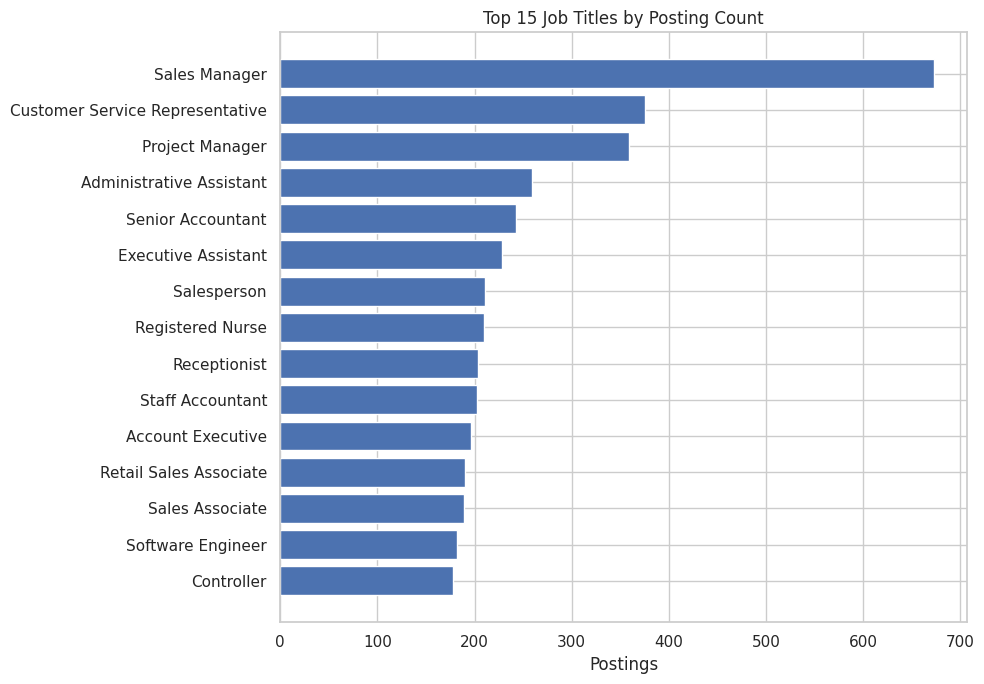

In [9]:
top_titles = df["title"].value_counts().head(15).sort_values()
display(top_titles.sort_values(ascending=False).to_frame("postings"))
plt.figure(figsize=(10,7)); plt.barh(top_titles.index, top_titles.values); plt.title("Top 15 Job Titles by Posting Count"); plt.xlabel("Postings"); plt.tight_layout(); plt.show()

## 5. Which companies post the most jobs?

### Question 5 — Where is job-posting activity concentrated among companies?

,postings
company_name,
Liberty Healthcare and Rehabilitation Services,1108
The Job Network,1003
J. Galt,604
TEKsystems,529
"Lowe's Companies, Inc.",527
Ingersoll Rand,517
Capital One,496
Cogent Communications,476
Insight Global,418


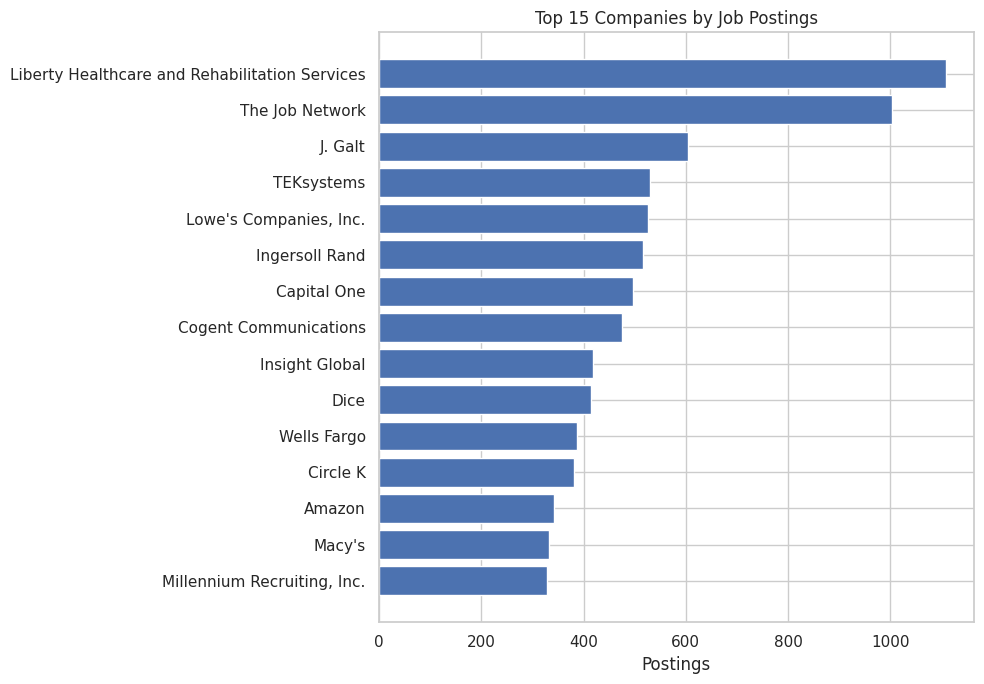

In [10]:
top_companies = df.dropna(subset=["company_name"])["company_name"].value_counts().head(15).sort_values()
display(top_companies.sort_values(ascending=False).to_frame("postings"))
plt.figure(figsize=(10,7)); plt.barh(top_companies.index, top_companies.values); plt.title("Top 15 Companies by Job Postings"); plt.xlabel("Postings"); plt.tight_layout(); plt.show()

## 6. What work arrangements dominate?

### Question 6 — Is the market mainly full-time, contract, part-time or other?

,postings
formatted_work_type,
Full-time,98814
Contract,12117
Part-time,9696
Temporary,1190
Internship,983
Volunteer,562
Other,487


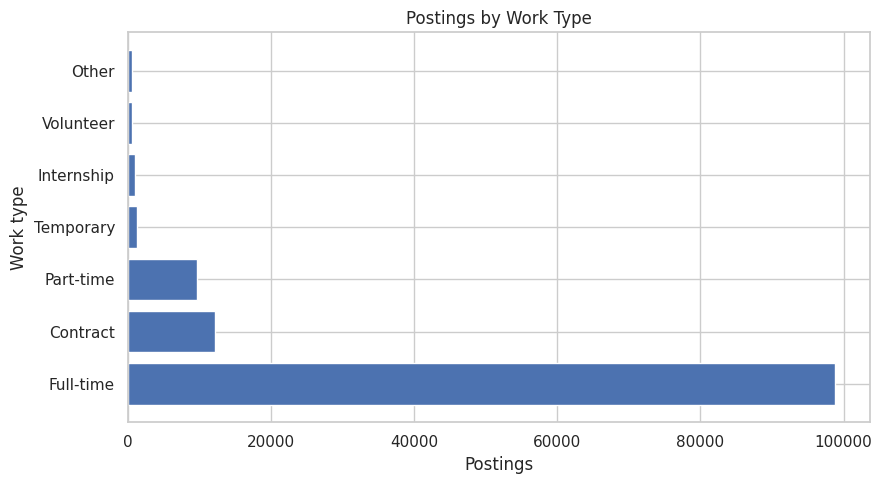

In [11]:
work = df["formatted_work_type"].value_counts()
display(work.to_frame("postings"))
plt.figure(figsize=(9,5)); plt.barh(work.index, work.values); plt.title("Postings by Work Type"); plt.xlabel("Postings"); plt.ylabel("Work type"); plt.tight_layout(); plt.show()

## 7. Experience level and demand

### Question 7 — Which experience levels have the most postings?

,postings
formatted_experience_level,
Mid-Senior level,41489
Entry level,36708
Not specified,29409
Associate,9826
Director,3746
Internship,1449
Executive,1222


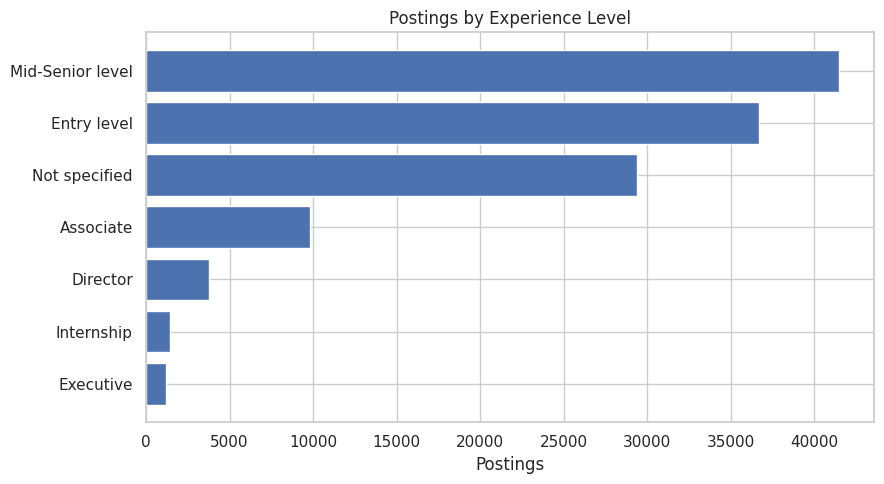

In [12]:
exp = df["formatted_experience_level"].fillna("Not specified").value_counts()
display(exp.to_frame("postings"))
plt.figure(figsize=(9,5)); plt.barh(exp.sort_values().index, exp.sort_values().values); plt.title("Postings by Experience Level"); plt.xlabel("Postings"); plt.tight_layout(); plt.show()

## 8. Salary analysis

### Question 8 — How is compensation distributed, and how much salary information is disclosed?

`normalized_salary` is used because the source contains multiple pay periods. Missing salary is not treated as zero.

Salary-disclosed postings: 36059 (29.1%)
Median normalized salary: 81500.0
Mean normalized salary: 205406.75560262348
Q1 / Q3: 52000.0 125000.0
Max: 535600000.0


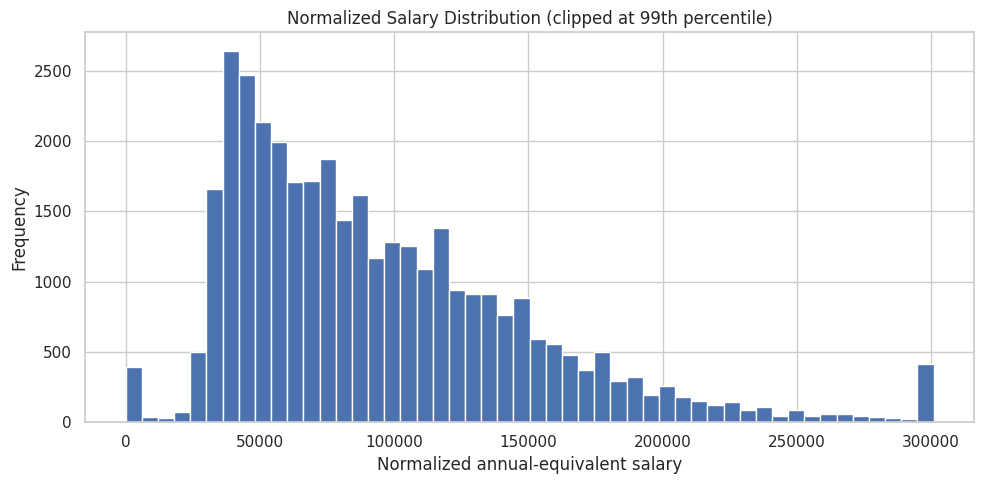

In [13]:
salary = df["normalized_salary"].dropna()
print("Salary-disclosed postings:", len(salary), f"({len(salary)/len(df):.1%})")
print("Median normalized salary:", salary.median())
print("Mean normalized salary:", salary.mean())
print("Q1 / Q3:", salary.quantile(.25), salary.quantile(.75))
print("Max:", salary.max())
plt.figure(figsize=(10,5)); plt.hist(salary.clip(upper=salary.quantile(.99)), bins=50); plt.title("Normalized Salary Distribution (clipped at 99th percentile)"); plt.xlabel("Normalized annual-equivalent salary"); plt.ylabel("Frequency"); plt.tight_layout(); plt.show()

### Question 9 — Does experience level relate to compensation?

Medians are emphasized because salary is skewed.

,postings,median_salary,mean_salary
formatted_experience_level,,,
Executive,382,"193,750.00","201,788.50"
Director,1268,"167,206.25","172,285.23"
Mid-Senior level,12908,"107,500.00","220,502.59"
Associate,3891,"72,800.00","81,875.99"
Entry level,9126,"52,213.20","246,989.17"
Internship,378,"48,880.00","963,207.07"


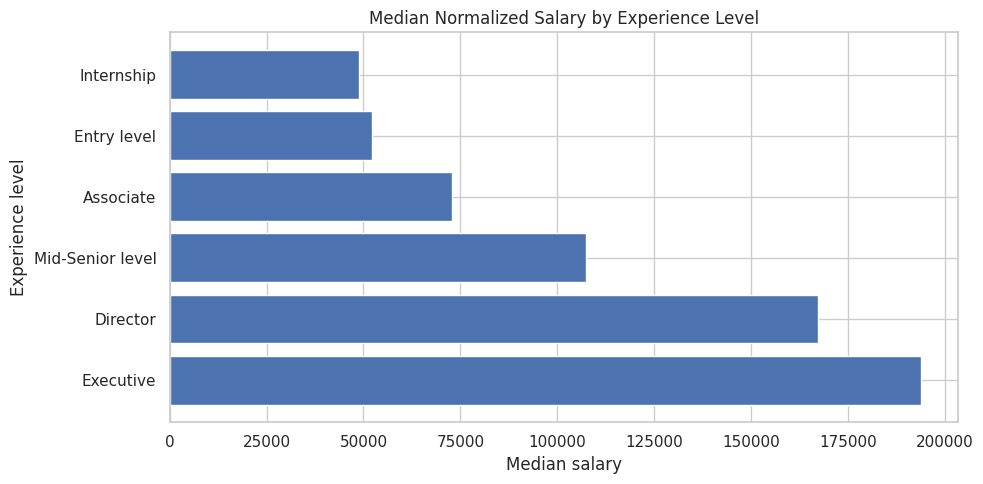

In [14]:
salary_exp = (df.dropna(subset=["normalized_salary"]).groupby("formatted_experience_level").agg(postings=("job_id","count"), median_salary=("normalized_salary","median"), mean_salary=("normalized_salary","mean")).sort_values("median_salary", ascending=False))
display(salary_exp)
plt.figure(figsize=(10,5)); plt.barh(salary_exp.index, salary_exp.median_salary); plt.title("Median Normalized Salary by Experience Level"); plt.xlabel("Median salary"); plt.ylabel("Experience level"); plt.tight_layout(); plt.show()

## 9. Demand versus application activity

### Question 10 — Do jobs with more views necessarily receive more applications?

Views and applications are sparse and skewed, so a log-scale scatter and Spearman correlation are used.

Rows with both positive views and applies: 23319
Spearman correlation: 0.8214148978507753


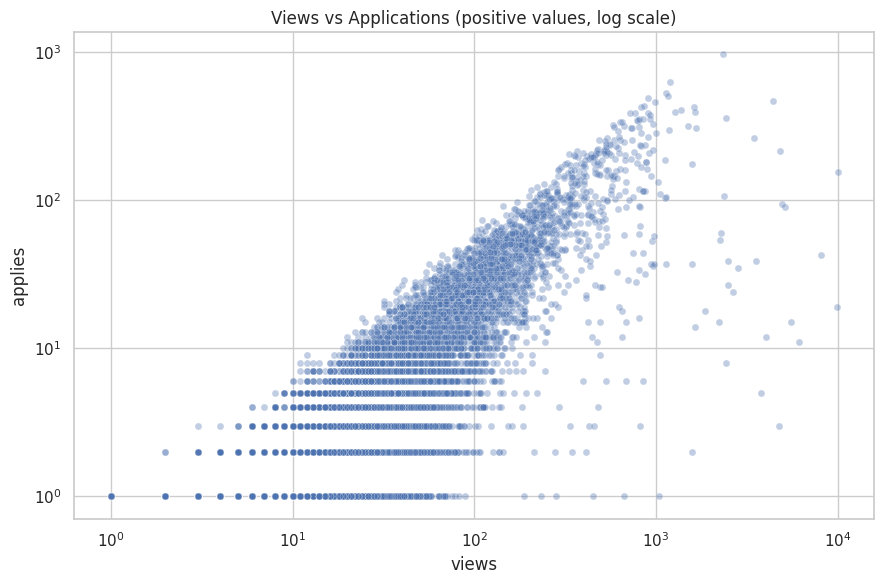

In [15]:
eng = df[(df.views > 0) & (df.applies > 0)][["views","applies"]].dropna()
print("Rows with both positive views and applies:", len(eng))
print("Spearman correlation:", eng.corr(method="spearman").loc["views","applies"])
sample = eng.sample(min(15000, len(eng)), random_state=42)
plt.figure(figsize=(9,6)); sns.scatterplot(data=sample, x="views", y="applies", alpha=.35, s=25); plt.xscale("log"); plt.yscale("log"); plt.title("Views vs Applications (positive values, log scale)"); plt.tight_layout(); plt.show()

## 10. Remote work

### Question 11 — How common are explicitly remote-eligible postings, and what is their salary profile?

In [16]:
remote = df["remote_allowed"].map({1.0:"Remote allowed", 0.0:"Not remote", np.nan:"Not specified"}).value_counts()
display(remote.to_frame("postings"))
print("Median salary among explicitly remote-eligible postings:", df.loc[df.remote_allowed.eq(1), "normalized_salary"].median())

,postings
remote_allowed,
Not specified,108603
Remote allowed,15246


Median salary among explicitly remote-eligible postings: 112500.0


## 11. Location analysis

### Question 12 — Which locations have the largest concentration of postings?

Location is ranked as supplied by the dataset; no assumption is made that every value represents the same geographic level.

,postings
location,
United States,8125
"New York, NY",2756
"Chicago, IL",1834
"Houston, TX",1762
"Dallas, TX",1383
"Atlanta, GA",1363
"Boston, MA",1176
"Austin, TX",1083
"Charlotte, NC",1075


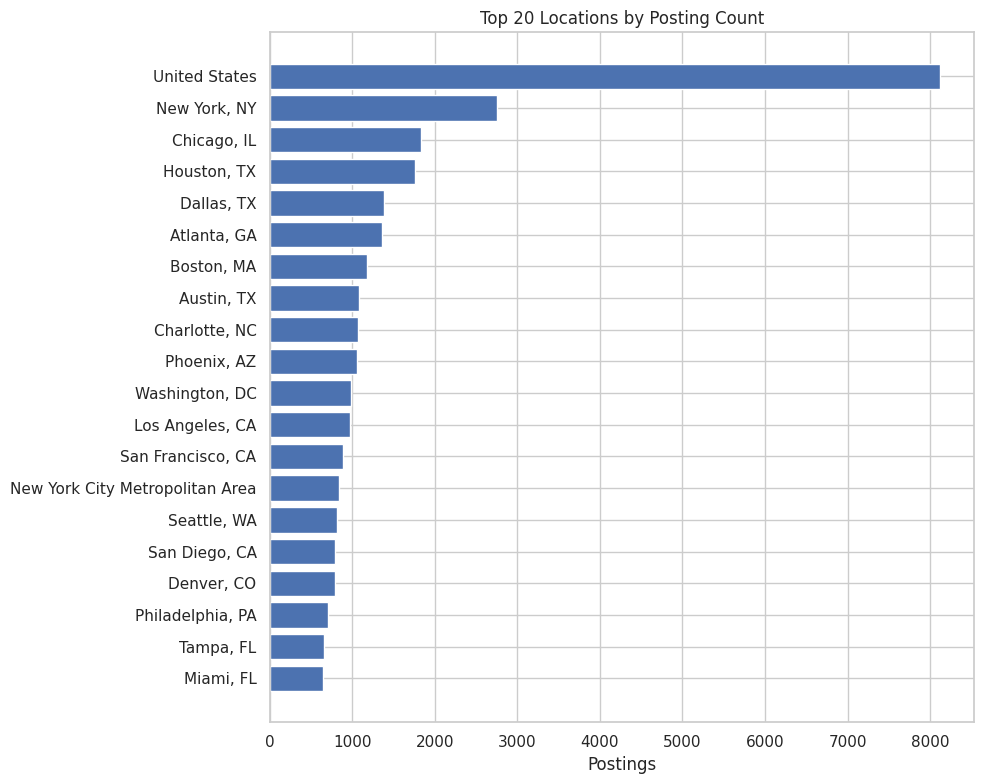

In [17]:
loc = df["location"].value_counts().head(20).sort_values()
display(loc.sort_values(ascending=False).to_frame("postings"))
plt.figure(figsize=(10,8)); plt.barh(loc.index, loc.values); plt.title("Top 20 Locations by Posting Count"); plt.xlabel("Postings"); plt.tight_layout(); plt.show()

## 12. Industry and skill demand using relational tables

The related tables let us analyze explicit industry and skill mappings rather than relying only on free-text descriptions.

In [17]:
job_ind = pd.read_csv(DATA_DIR / "jobs" / "job_industries.csv")
industries = pd.read_csv(DATA_DIR / "mappings" / "industries.csv")
job_skills = pd.read_csv(DATA_DIR / "jobs" / "job_skills.csv")
skills = pd.read_csv(DATA_DIR / "mappings" / "skills.csv")
job_ind = job_ind.merge(industries, on="industry_id", how="left")
job_skills = job_skills.merge(skills, on="skill_abr", how="left")
print("Industry-job rows:", job_ind.shape)
print("Skill-job rows:", job_skills.shape)

Industry-job rows: (164808, 3)
Skill-job rows: (213768, 3)


### Question 13 — Which industries have the largest posting presence?

,job-industry links
industry_name,
Hospitals and Health Care,18326
Retail,11033
IT Services and IT Consulting,10396
Staffing and Recruiting,9005
Financial Services,8535
Software Development,5091
Manufacturing,3689
Construction,3445
Banking,2923


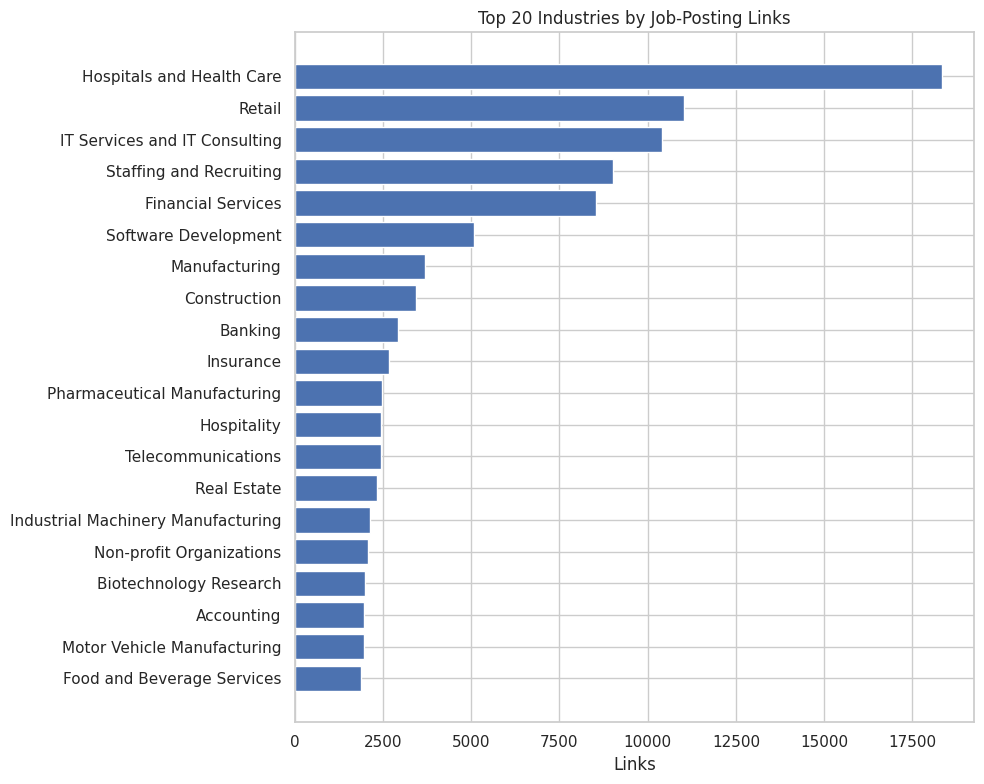

In [18]:
industry_counts = job_ind["industry_name"].value_counts().head(20).sort_values()
display(industry_counts.sort_values(ascending=False).to_frame("job-industry links"))
plt.figure(figsize=(10,8)); plt.barh(industry_counts.index, industry_counts.values); plt.title("Top 20 Industries by Job-Posting Links"); plt.xlabel("Links"); plt.tight_layout(); plt.show()

### Question 14 — Which skills are most frequently requested?

A posting can have multiple skills, so these are skill-job relationships, not unique job counts.

,skill-job links
skill_name,
Information Technology,26137
Sales,22475
Management,20861
Manufacturing,18185
Health Care Provider,17369
Business Development,14290
Engineering,13009
Other,12608
Finance,8540


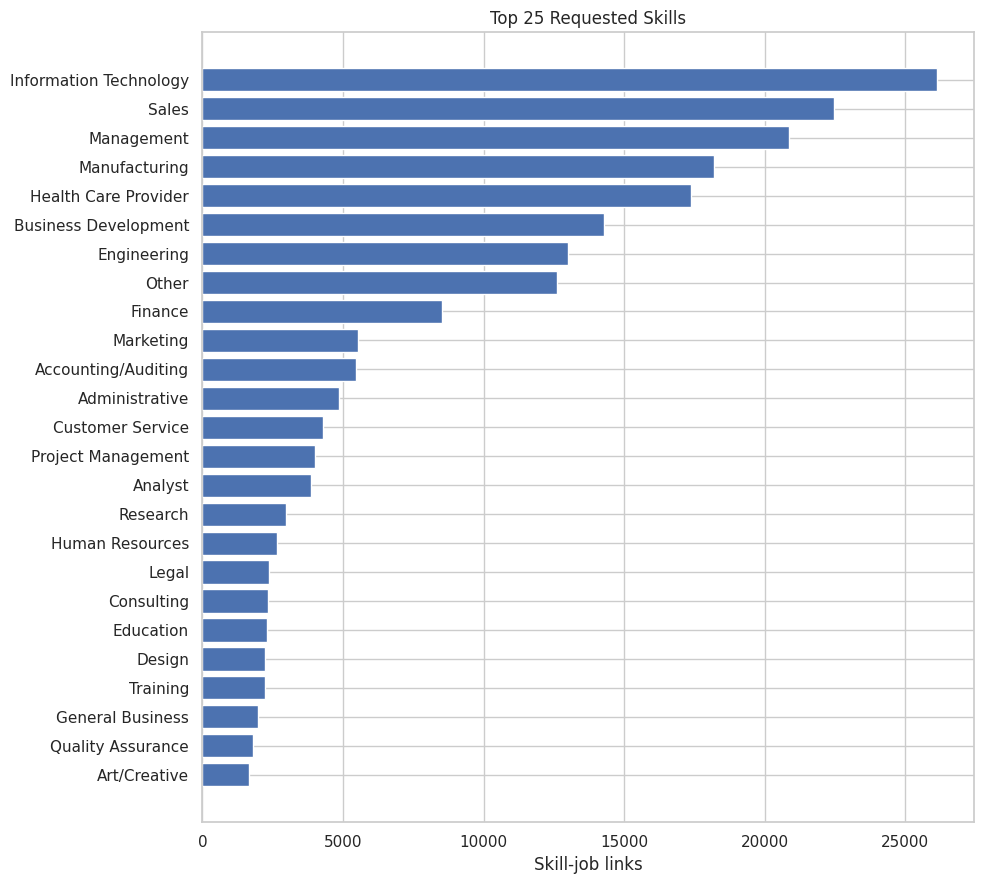

In [19]:
skill_counts = job_skills["skill_name"].value_counts().head(25).sort_values()
display(skill_counts.sort_values(ascending=False).to_frame("skill-job links"))
plt.figure(figsize=(10,9)); plt.barh(skill_counts.index, skill_counts.values); plt.title("Top 25 Requested Skills"); plt.xlabel("Skill-job links"); plt.tight_layout(); plt.show()

## 13. Skills and compensation

### Question 15 — Which frequently requested skills appear in higher-paying postings?

Only skills with at least 100 salary-disclosed postings are ranked to reduce unstable small-sample results.

In [20]:
skill_salary = job_skills[["job_id","skill_name"]].merge(df[["job_id","normalized_salary"]], on="job_id", how="inner").dropna(subset=["normalized_salary"])
skill_salary_summary = (skill_salary.groupby("skill_name").agg(job_count=("job_id","nunique"), median_salary=("normalized_salary","median")).query("job_count >= 100").sort_values("median_salary", ascending=False))
display(skill_salary_summary.head(20))

,job_count,median_salary
skill_name,,
Product Management,475,"140,500.00"
Strategy/Planning,473,"120,643.50"
Legal,980,"120,000.00"
Engineering,3778,"120,000.00"
Consulting,795,"114,400.00"
Project Management,1442,"114,400.00"
Information Technology,7177,"112,500.00"
Advertising,235,"94,050.00"
Research,933,"93,600.00"


## 14. Skill combinations

### Question 16 — Which skills commonly occur together?

In [21]:
pairs = job_skills[["job_id","skill_name"]].dropna().drop_duplicates().merge(job_skills[["job_id","skill_name"]].dropna().drop_duplicates(), on="job_id")
pairs = pairs[pairs.skill_name_x < pairs.skill_name_y]
pair_counts = pairs.groupby(["skill_name_x","skill_name_y"]).size().sort_values(ascending=False).head(20)
display(pair_counts.to_frame("co_occurrences"))

co_occurrences
skill_name_x           skill_name_y                          
Management             Manufacturing                    16336
Business Development   Sales                            13164
Engineering            Information Technology            9090
Accounting/Auditing    Finance                           3735
Finance                Sales                             3569
Marketing              Sales                             2340
Analyst                Research                          2242
                       Information Technology            2196
Information Technology Project Management                2144
                       Research                          1959
Education              Training                          1833
Art/Creative           Design                            1466
Design                 Information Technology            1441
Art/Creative           Information Technology            1368
Customer Service       Sales                             1335
Marketing              Public Relations                  1164
                       Writing/Editing                   1080
Public Relations       Writing/Editing                   1036
Information Technology Other                              992
Management             Other                              933

## 15. High-demand vs high-paying opportunities

### Question 17 — Which roles combine substantial posting volume with above-median compensation?

Titles are required to have at least 30 salary observations.

In [23]:
title_market = (df.dropna(subset=["normalized_salary"]).groupby("title").agg(postings=("job_id","count"), median_salary=("normalized_salary","median")).query("postings >= 30"))
market_median = df.normalized_salary.median()
top_opportunities = title_market[title_market.median_salary >= market_median].sort_values(["postings","median_salary"], ascending=False).head(25)
display(top_opportunities)

,postings,median_salary
title,,
Senior Accountant,143,"90,000.00"
Project Manager,124,"112,410.00"
Controller,98,"135,000.00"
Accounting Manager,67,"102,500.00"
Software Engineer,61,"139,360.00"
Registered Nurse,60,"94,640.00"
Senior Software Engineer,57,"154,132.00"
Financial Analyst,53,"82,500.00"
Electrical Engineer,45,"103,500.00"


## 16. Outlier and data-quality investigation

### Question 18 — Are extreme salary values present, and should they automatically be removed?

No. We flag them for investigation instead of deleting them blindly.

In [24]:
q1, q3 = df.normalized_salary.quantile([.25,.75]); iqr = q3-q1; lower, upper = q1-1.5*iqr, q3+1.5*iqr
salary_outliers = df[df.normalized_salary.notna() & ((df.normalized_salary < lower) | (df.normalized_salary > upper))]
print("IQR lower bound:", lower); print("IQR upper bound:", upper); print("Potential salary outliers:", len(salary_outliers))
display(salary_outliers[["title","location","pay_period","min_salary","max_salary","normalized_salary"]].head(20))

IQR lower bound: -57500.0
IQR upper bound: 234500.0
Potential salary outliers: 952


,title,location,pay_period,min_salary,max_salary,normalized_salary
188,Primary Care Leader Needed,"Fresno, CA",YEARLY,"275,000.00","297,000.00","286,000.00"
202,Medical Consultant,"Brooklyn, NY",HOURLY,NaN,NaN,"624,000.00"
338,Real Estate Sales Agent,"Austin, Texas Metropolitan Area",YEARLY,"80,000.00","400,000.00","240,000.00"
369,Hiring a Contract Lawyer with Probate Experience,"Phoenix, AZ",HOURLY,125.00,180.00,"317,200.00"
401,Investment Real Estate Sales Advisor,"Dallas, TX",YEARLY,"100,000.00","700,000.00","400,000.00"
403,Deputy City Manager - Chief Financial Officer,"Tempe, AZ",YEARLY,"205,398.00","274,206.00","239,802.00"
425,Labor And Employment Attorney,"Palo Alto, CA",YEARLY,"420,000.00","435,000.00","427,500.00"
445,Sales Executive,United States,YEARLY,"200,000.00","400,000.00","300,000.00"
520,Senior Machine Learning Research Engineer,San Francisco Bay Area,YEARLY,"150,000.00","350,000.00","250,000.00"
628,Medical Doctor,"California, United States",HOURLY,250.00,275.00,"546,000.00"


## 17. Correlation and relationship screening

### Question 19 — Which numeric engagement and compensation variables move together?

Correlation is a screening tool, not proof of causation.

,views,applies,normalized_salary,min_salary,max_salary
views,1.00,0.82,0.13,0.09,0.09
applies,0.82,1.00,0.12,0.03,0.01
normalized_salary,0.13,0.12,1.00,0.80,0.81
min_salary,0.09,0.03,0.80,1.00,0.97
max_salary,0.09,0.01,0.81,0.97,1.00


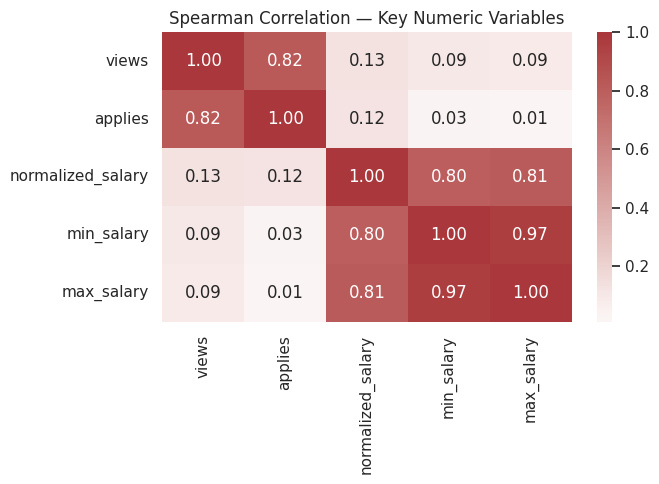

In [25]:
num_cols = ["views","applies","normalized_salary","min_salary","max_salary"]
corr = df[num_cols].corr(method="spearman")
display(corr)
plt.figure(figsize=(7,5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0); plt.title("Spearman Correlation — Key Numeric Variables"); plt.tight_layout(); plt.show()

# 18. Executive findings

These conclusions are intentionally limited to what the dataset supports:

1. The dataset contains **123,849 job postings**, with very high diversity in titles and locations.
2. **Full-time roles dominate** the postings, while contract and part-time roles form smaller segments.
3. Salary information is **not available for most postings**, so salary analysis represents the disclosed-salary subset rather than the entire market.
4. Explicit skill and industry mappings allow stronger demand analysis than title-only EDA.
5. Experience, work type, location and skills can be compared with normalized salary, but these are **associations, not causal effects**.
6. Views and applications are sparse and skewed, making log-scale and non-parametric summaries appropriate.
7. The source period is 2023–2024, so the project should not claim that results represent the live 2026 market.

# 19. Business recommendations

### For candidates
- Prioritize skills that appear frequently in target roles.
- Compare skill bundles rather than learning isolated tools.
- Treat salary conclusions carefully because disclosure is incomplete.

### For recruiters / employers
- Compare application activity with views to identify postings that attract attention but fail to convert that attention into applications.
- Benchmark compensation by experience, industry and location using sufficient sample sizes.
- Monitor remote/work-type differences when designing job strategies.

### For analysts
- Preserve missingness where it has business meaning.
- Normalize pay periods before salary comparisons.
- Use relational tables for skills and industries instead of relying only on free-text descriptions.